In [1]:
import numpy as np
from matplotlib import pyplot as plt

# Continuation (radial equation with Robin bc)

In [2]:
def w(h):
    return (h**(-5)/5 + h**(-2)/2)
def dw(h):
    return (- h**(-6) + h**(-3))
def ddw(h):
    return (6*h**(-7) - 3*h**(-4))

In [3]:
# Continuation to compute h0in for different values of hmax or h0out
data = np.loadtxt(
    "continuation/2D_continuation.txt",
    delimiter=',',
    unpack=True
)
numrows = len(data[0,:])
K1 = data[1:, numrows-8]
K2 = data[1:, numrows-7]
GradW1 = data[1:, numrows-6]
GradW2 = data[1:, numrows-5]
H0out_lim = data[1:, numrows-4]
Hmax = data[1:, numrows-10]
h0out_formula = data[1:, numrows-9]
V = data[1:, numrows-11]
I = data[1:, numrows-12]
K = data[1:, numrows-13]
Omega = data[1:, numrows-14]
# Continuation (need to remove by hand (why???) the unstable branch)
par = data[1:, 3]
index = data[1:, 0]

i_branch = 16

In [4]:
from pathlib import Path
import numpy as np
import re
from matplotlib import pyplot as plt


def analyze_simulation(directory):

    directory = Path(directory)

    results = []

    for filename in sorted(directory.glob("*.txt")):

        # Read header
        with open(filename, "r") as f:
            header = f.readline().strip()

        # Extract time from "@time=..."
        match = re.search(r"@time=([0-9.eE+-]+)", header)

        if match is None:
            print(f"Could not find time in {filename}")
            continue

        time = float(match.group(1))

        # Read x, y, h, p
        data = np.loadtxt(filename, comments="#")

        x = data[:, 0]
        y = data[:, 1]
        h = data[:, 2]

        # Only consider points where y=0
        mask = y == 0  
        x = x[mask]
        h = h[mask]
        sort_indices = np.argsort(x)
        x = x[sort_indices]
        h = h[sort_indices]

        #plt.plot(x,h,'*')  # To see if points are enough for parabolic fit

        # Location of maximum h
        i = np.argmax(h)
        xmax = x[i]
        hmax = h[i]

        npoints = 5  # Number of points to use for quadratic fit
        # Select npoints centered as much as possible around the maximum
        half = npoints // 2
        i0 = max(0, i - half)
        i1 = min(len(x), i0 + npoints)

        # Correct for boundary cases
        i0 = max(0, i1 - npoints)

        xx = x[i0:i1]
        yy = h[i0:i1]

        # Fit quadratic: y = a*x^2 + b*x + c
        a, b, c = np.polyfit(xx, yy, 2)

        # Vertex of parabola
        xmax = -b / (2 * a)

        results.append([time, xmax, hmax])

    # Sort by time
    results = np.array(results)
    results = results[np.argsort(results[:, 0])]

    return results

# Example of how I measure $\dot{x}$

4.1371119885799015
-2.9146448731907083e-08


/tmp/ipykernel_998972/1790128828.py:55: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  plt.plot(np.linspace(-2,2,100), p(np.linspace(-2,2,100)), 'r-',color='black')  # Plot the fitted parabola
/tmp/ipykernel_998972/1790128828.py:68: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  plt.plot(tt,p(tt),'r-',color='black')  # Plot the fitted line


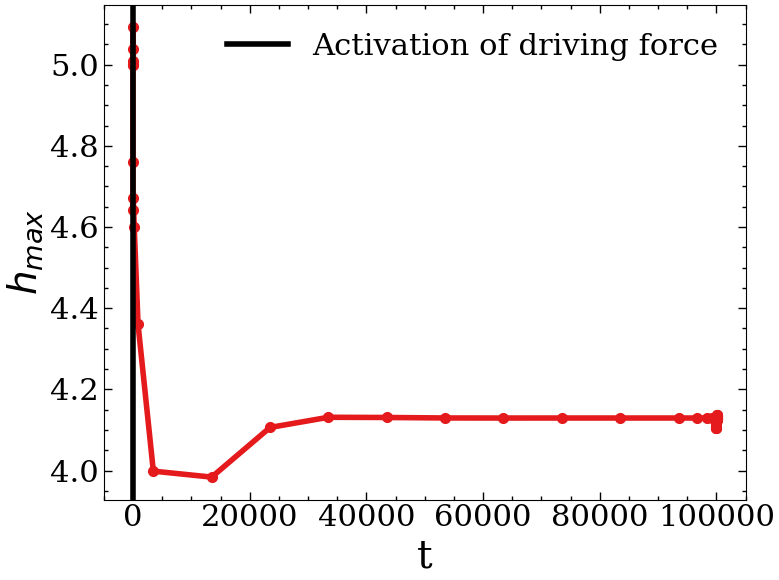

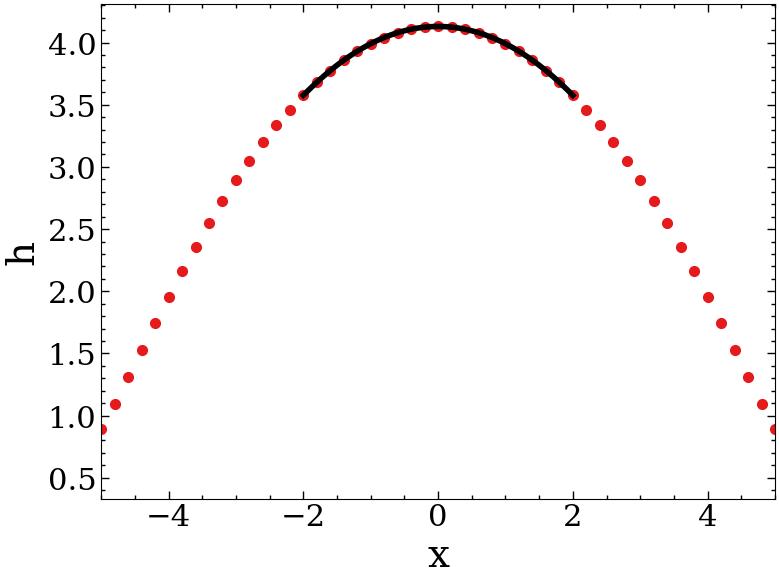

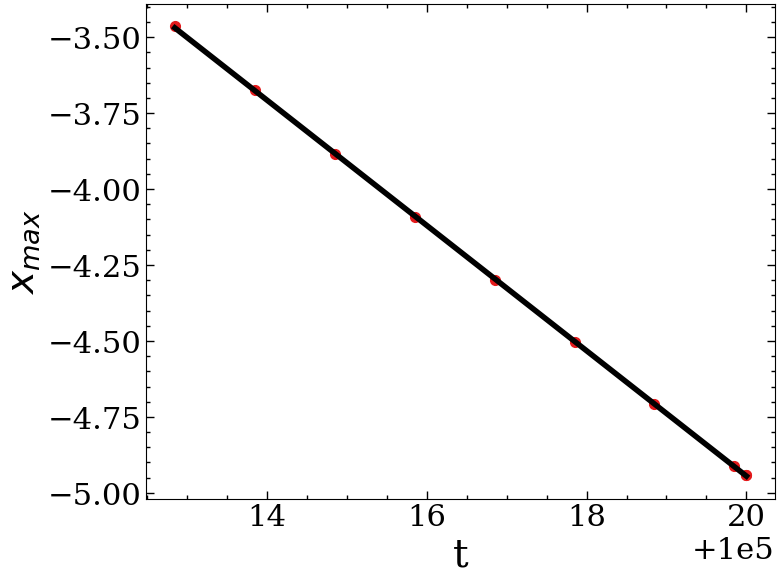

In [13]:
ha=0.5
eps=0.0125
hc=5
# Read hmax(t)
res=analyze_simulation(f"pbc_hcenter_{hc:g}_c=1_eps={eps:g}/domain")
hmax_ = res[-1,2]

### Decay of hmax(t)
hmaxvec=res[:,2]
ttvec=res[:,0]
plt.xlabel('t')
plt.ylabel('$h_{max}$')
plt.plot(ttvec-6,hmaxvec,'.-') # Check if hmax converges in the simulation time
plt.axvline(0, label='Activation of driving force',color='black')  # Activation of driving force
plt.legend()
plt.savefig('hmax_decay.png')

### Fit of xmax(t)
plt.figure()
plt.xlabel('x')
plt.ylabel('h')
print(hmax_)
# Read x, y, h, p
filename = f"pbc_hcenter_{hc:g}_c=1_eps={eps:g}/domain/domain_000015.txt"   # t = 8
data = np.loadtxt(filename, comments="#")

x = data[:, 0]
y = data[:, 1]
h = data[:, 2]
# Only consider points where y=0
mask = y == 0  
x = x[mask]
h = h[mask]
sort_indices = np.argsort(x)
x = x[sort_indices]
h = h[sort_indices]
plt.plot(x,h,'.')  # To see if points are enough for parabolic fit
plt.xlim(-5,5)
# Location of maximum h
i = np.argmax(h)
xmax = x[i]
hmax = h[i]
npoints = 5  # Number of points to use for quadratic fit
# Select npoints centered as much as possible around the maximum
half = npoints // 2
i0 = max(0, i - half)
i1 = min(len(x), i0 + npoints)
# Correct for boundary cases
i0 = max(0, i1 - npoints)
xx = x[i0:i1]
yy = h[i0:i1]
# Fit quadratic: y = a*x^2 + b*x + c
a, b, c = np.polyfit(xx, yy, 2)
p = np.poly1d([a, b, c])
plt.plot(np.linspace(-2,2,100), p(np.linspace(-2,2,100)), 'r-',color='black')  # Plot the fitted parabola
xmax = -b / (2 * a)
print(xmax)

### Fit of xdot
plt.figure()
plt.ylabel('$x_{max}$')
plt.xlabel('t')
xx = np.array(res[-10:,1])
tt = np.array(res[-10:,0])
c = np.polyfit(tt,xx,deg=1)
p = np.poly1d(c)
plt.plot(tt,xx,'.')
plt.plot(tt,p(tt),'r-',color='black')  # Plot the fitted line
#plt.plot(res[:,0],res[:,1])

# Validation for BULK FORCE
We consider that $A$ is homogeneous, while $W=Aw(h)+ch\sin(2\pi \chi)$ with $c=1$ and $\chi=\epsilon x$

# Pismen (2004)

$$3\eta \theta^{-1}h_a^{-2} \mathbf{U}\epsilon^{-1} K_{\text{Pismen}}=-2\pi \cos(2\pi \epsilon x)h_ac V$$
where 
$$K_{\text{Pismen}} = K+h_m^{-2}I$$
and $U/\epsilon = v_1$

# Our formula
$$3 \eta h_{a}^{-1}K v_{1}=-2\pi \cos(2\pi \epsilon x)h_ac V+I(2\pi \cos(2\pi \epsilon x)h_ac +\partial_{\chi}H_{0}^{\mathrm{out}}
A h_{a}^{-2}
\partial_{HH}\omega(H_{0}^{\mathrm{out}}))$$

# For an almost flat outer film

4.1371119885799015


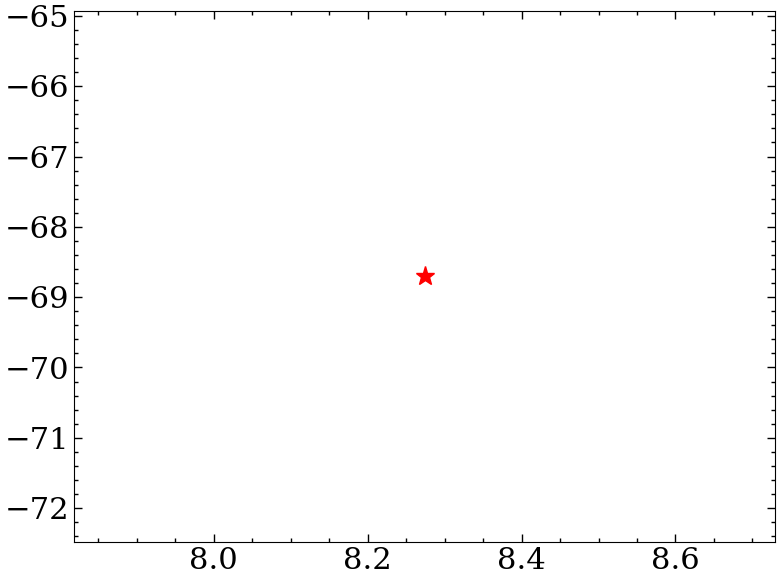

In [ ]:
# First epsilon
fig,ax = plt.subplots()
ha=0.5
eps=0.0125

hcvec = [4,5,6]
hmax_vec = []
xdot_vec = []
#grad_chi_vec = []
for hc in hcvec:
    # Read hmax(t)
    res=analyze_simulation(f"pbc_hcenter_{hc:g}_c=1_eps={eps:g}/domain")
    hmax_ = res[-1,2]
    #hmaxvec=res[:,2]
    #ttvec=res[:,0]
    #plt.semilogy(ttvec,hmaxvec) # Check if hmax converges in the simulation time
    print(hmax_)

    #data = np.loadtxt(f"pbc_hcenter_{hc:g}_c=1_eps={eps:g}/obs.txt", skiprows=1)
    """
    # Read xcm(t) and grad_chi h(t)
    t = data[:,0]
    xcm = data[:,3]/data[:,2]   # Numerator and denominator integrals are computed separately
    c=np.polyfit(t[-5:-1],xcm[-5:-1],deg=1)
    """
    xx = np.array(res[-25:,1])
    tt = np.array(res[-25:,0])
    #plt.plot(tt,xx,'.') # Check that the last 10 points are enough to fit a line and not too many to see before drop motion
    c = np.polyfit(tt,xx,deg=1)
    #plt.plot(res[:,0],res[:,1])
    #plt.plot(tt, np.polyval(c,tt), '--',color='black')
    #grad_chi_vec.append(ha**(-1)*data[-1,1])
    # Fit xdot from xcm(t)
    
    xdot_vec.append(c[0])
    hmax_vec.append(hmax_)
#plt.xlim(-5,5)

ax.plot(np.array(hmax_vec)/ha,np.array(xdot_vec)/(eps*ha**2),'*',color='red')


# For a relaxed (long time limit) outer film

In [ ]:
# First epsilon
#fig,ax = plt.subplots()
#ha=0.5
#eps=0.001

hcvec = [3,5,7,13,15,20,25]
hmax_vec = []
xdot_vec = []
#grad_chi_vec = []
for hc in hcvec:
    # Read hmax(t)
    res=analyze_simulation(f"pbc_hcenter_{hc:g}_c=1_eps={eps:g}_relaxed/domain")
    hmax_ = res[-1,2]
    #hmaxvec=res[:,2]
    #ttvec=res[:,0]
    #plt.semilogy(ttvec,hmaxvec) # Check if hmax converges in the simulation time
    print(hmax_)

    #data = np.loadtxt(f"pbc_hcenter_{hc:g}_c=1_eps={eps:g}_relaxed/obs.txt", skiprows=1)
    """
    # Read xcm(t) and grad_chi h(t)
    t = data[:,0]
    xcm = data[:,3]/data[:,2]   # Numerator and denominator integrals are computed separately
    c=np.polyfit(t[-5:-1],xcm[-5:-1],deg=1)
    """
    xx = np.array(res[-25:,1])
    tt = np.array(res[-25:,0])
    #plt.plot(tt,xx,'.') # Check that the last 10 points are enough to fit a line and not too many to see before drop motion
    #plt.axvline(x=tt[-1], color='black', linestyle='--')
    c = np.polyfit(tt,xx,deg=1)
    #plt.plot(res[:,0],res[:,1])
    #plt.plot(tt, np.polyval(c,tt), '--',color='black')
    #grad_chi_vec.append(ha**(-1)*data[-1,1])
    # Fit xdot from xcm(t)
    
    xdot_vec.append(c[0])
    hmax_vec.append(hmax_)

ax.plot(np.array(hmax_vec)/ha,np.array(xdot_vec)/(eps*ha**2),'*',color='blue')

1.6469453043664144
2.142179627759655
2.548561927652561
3.4683191844846415
3.71042939207274
4.273054415073035
4.754312665761613


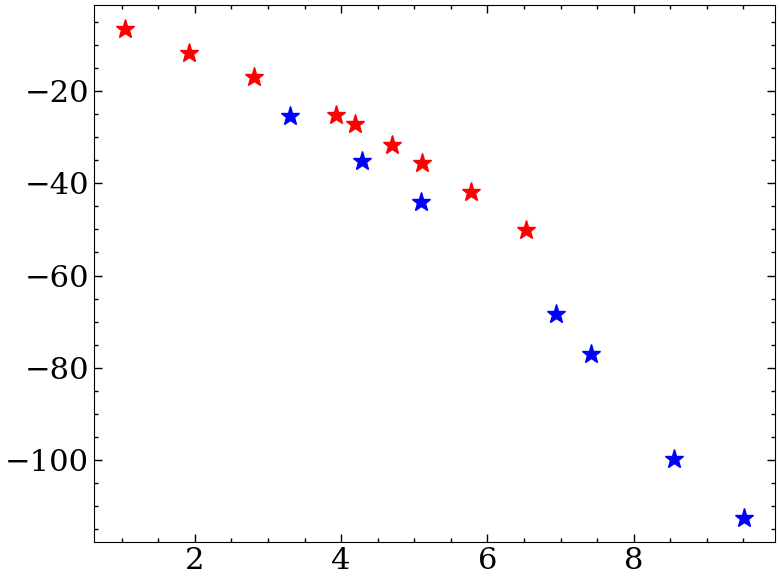

In [ ]:
fig

In [ ]:
.

SyntaxError: invalid syntax (1933637684.py, line 1)

# Use the formula with continuations results

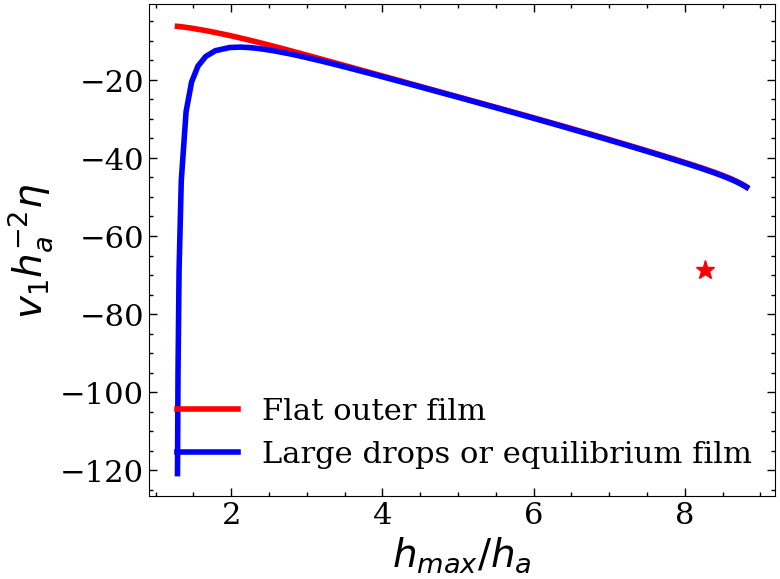

In [15]:
# Our full formula
#grad_chi_Hout = -ha**4/3
#formula = (-2*np.pi*(V-I)+I*grad_chi_Hout*ddw(H0out_lim)*ha**(-3))/(3*K)
#formula = (-2*np.pi*(V-I)-I*2*np.pi)/(3*K)
#Hmax = np.linspace(min(Hmax),max(Hmax),100)

formula_flat = -2*np.pi*(V-I)/(3*K)
ax.plot(Hmax, formula_flat,'-',label='Flat outer film',color='red')
# Our formula in the 'large drop limit' or equilibrium limit
formula_largedrop = -2*np.pi*V/(3*K)
ax.plot(Hmax, formula_largedrop,'-',label='Large drops or equilibrium film',color='blue')
ax.set_xlabel('$h_{max}/h_a$')
ax.set_ylabel('$v_1h_a^{-2}\\eta$')
ax.legend()
fig

In [ ]:

## Flat outer film
# Psimen (2004) with B
Kp = K
formula_Pismen = -2*np.pi*(V-I)/(3*Kp)
ax.plot(Hmax, formula_Pismen,'-',label='Pismen $B\\neq 0$',color='black',lw='2')
# Psimen (2004) withOUT B
Kp = K+H0out_lim**(-2)*I
formula_Pismen = -2*np.pi*V/(3*Kp)
ax.plot(Hmax, formula_Pismen,'--',label='Pismen $B=0$',color='black')

## Equilibrium outer film
# Psimen (2004) with B
Kp = K
formula_Pismen = -2*np.pi*(V-0.33*dhOmega)/(3*Kp)
ax.plot(Hmax, formula_Pismen,'-',color='black',lw='2')
# Psimen (2004) withOUT B
Kp = K+H0out_lim**(-2)*I
formula_Pismen = -2*np.pi*(V-0.33*dhOmega)/(3*Kp)
ax.plot(Hmax, formula_Pismen,'--',color='black')


ax.set_xlabel('$h_{max}/h_a$')
ax.legend()
ax.set_ylabel('$\\eta h_a^{-2} v_1 $')
fig.savefig('1D_pbc_validation.pdf',bbox_inches='tight')
fig

NameError: name 'dhOmega' is not defined

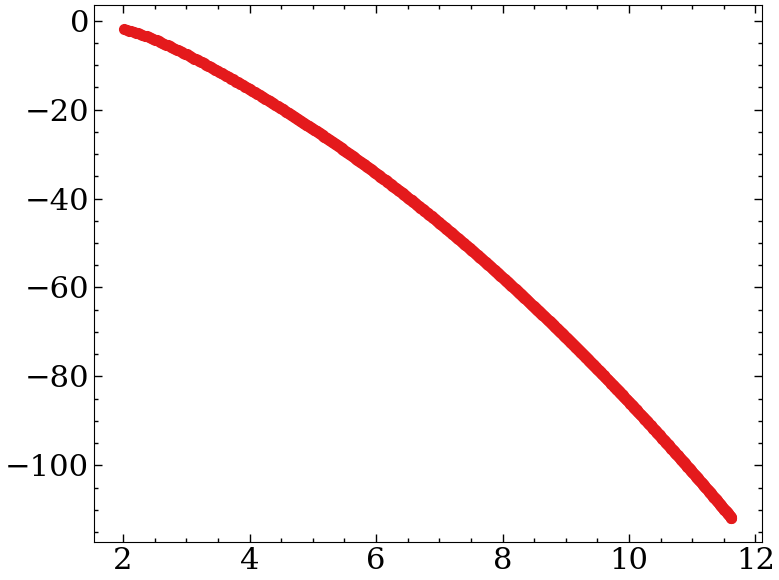

In [ ]:
plt.plot(Hmax,-2*np.pi*(V-0.33*dhOmega)/(3*Kp),'.')

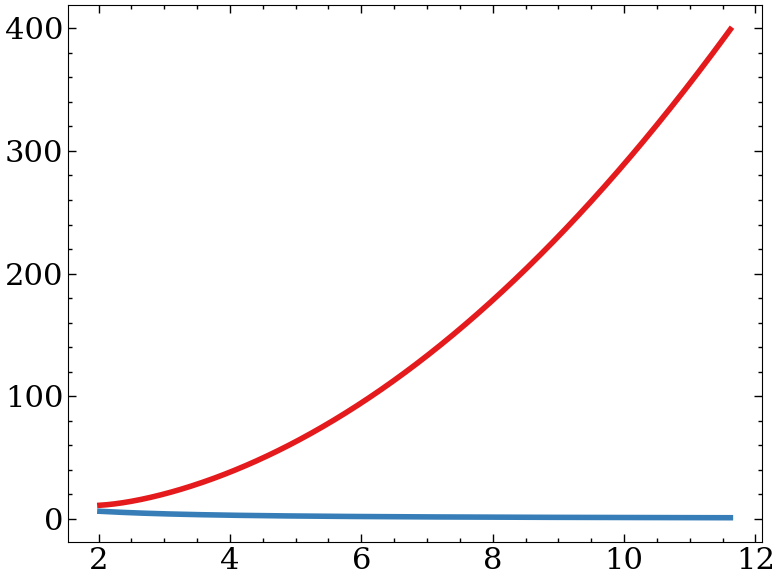

In [ ]:
plt.plot(Hmax, V)
plt.plot(Hmax, 0.33*dhOmega)